# Ziel des ML-AnsatzesFeature-Skalierung: 

1. Standardisierung der 5 Composite-Signale mittels StandardScaler.
2. K-Means Clustering ($K=5$): Der Algorithmus sucht völlig eigenständig nach 5 natürlichen Mathematischen Clustern in den Daten.
3. PCA (2D-Projektion): Reduktion der 5 Dimensionen auf 2 Hauptkomponenten ($PC_1, PC_2$), damit wir die Cluster im 2D-Streudiagramm visualisieren können.
4. Vergleich & Alignment

# Zelle 1: Imports & Daten vorbereiten

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. Indizes & Fuzzy-Assignments laden
df_indices = pd.read_csv('data/traveltide_user_perk_indices.csv')
df_fuzzy = pd.read_csv('data/perk_assignments.csv')

index_cols = ['meal_index', 'baggage_index', 'cancellation_index', 'bargain_hunter_index', 'free_night_index']
X = df_indices[index_cols]

# 2. Standardisierung für K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Daten für {len(df_indices):,} User erfolgreich skaliert.")

Daten für 50,000 User erfolgreich skaliert.


# Zelle 2: K-Means Clustering ($K=5$) & Silhouette Score

In [3]:
# K-Means Modell mit K=5 Clustern anlegen
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_indices['cluster_ml'] = kmeans.fit_predict(X_scaled)

# Silhouette Score berechnen (auf Stichprobe wegen Performance)
sample_size = min(10000, len(X_scaled))
sil_score = silhouette_score(X_scaled[:sample_size], df_indices['cluster_ml'].iloc[:sample_size])

print(f"=== K-Means Clustering abgeschlossen ===")
print(f"Silhouette Score (N={sample_size}): {sil_score:.4f}")
print("\nVerteilung der Kunden auf die 5 ML-Cluster:")
print(df_indices['cluster_ml'].value_counts().sort_index())

=== K-Means Clustering abgeschlossen ===
Silhouette Score (N=10000): 0.2628

Verteilung der Kunden auf die 5 ML-Cluster:
cluster_ml
0     9921
1     4728
2    16039
3    10343
4     8969
Name: count, dtype: int64


# Zelle 3: PCA (Principal Component Analysis) für 2D-Visualisierung

Erklärte Varianz durch PC1 & PC2: 62.9% (PC1: 37.0%, PC2: 25.9%)


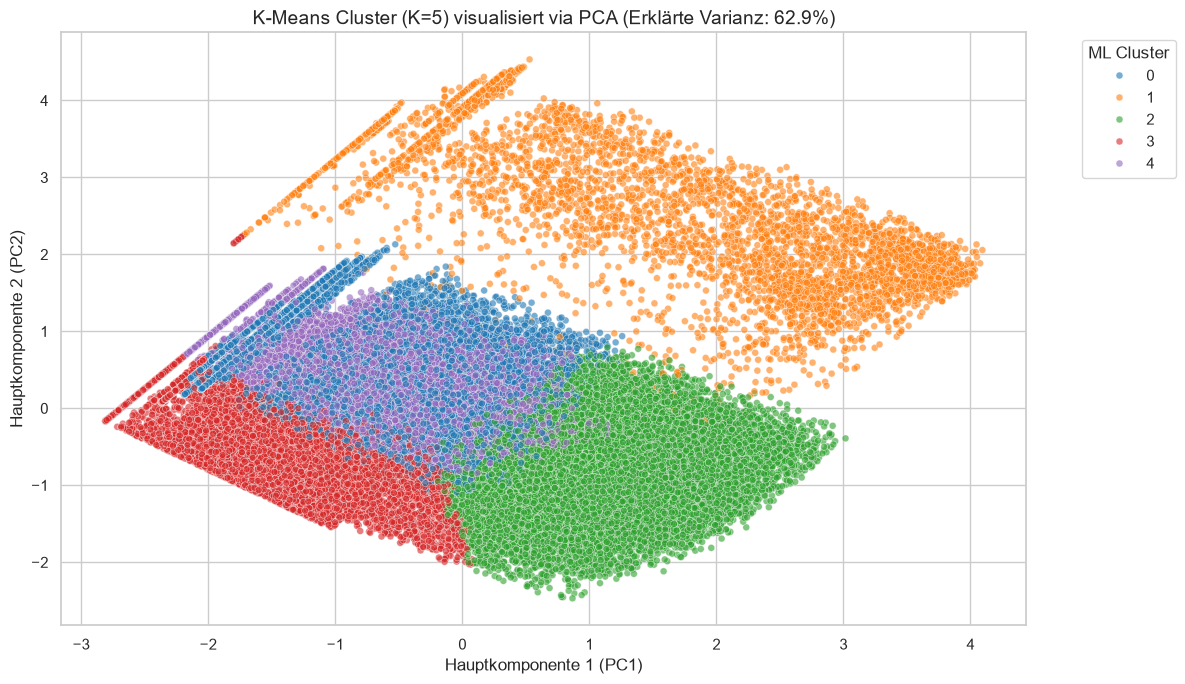

In [4]:
# PCA auf 2 Dimensionen reduzieren
pca = PCA(n_components=2, random_state=42)
pca_components = pca.fit_transform(X_scaled)

df_indices['PC1'] = pca_components[:, 0]
df_indices['PC2'] = pca_components[:, 1]

var_exp = pca.explained_variance_ratio_
print(f"Erklärte Varianz durch PC1 & PC2: {sum(var_exp)*100:.1f}% (PC1: {var_exp[0]*100:.1f}%, PC2: {var_exp[1]*100:.1f}%)")

# Scatterplot der 5 ML-Cluster
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df_indices, 
    x='PC1', y='PC2', 
    hue='cluster_ml', 
    palette='tab10', 
    alpha=0.6, 
    s=25
)

plt.title(f"K-Means Cluster (K=5) visualisiert via PCA (Erklärte Varianz: {sum(var_exp)*100:.1f}%)", fontsize=14)
plt.xlabel("Hauptkomponente 1 (PC1)")
plt.ylabel("Hauptkomponente 2 (PC2)")
plt.legend(title="ML Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Zelle 4: Vergleich: ML Cluster vs. Fuzzy Perk Assignments (Crosstab)

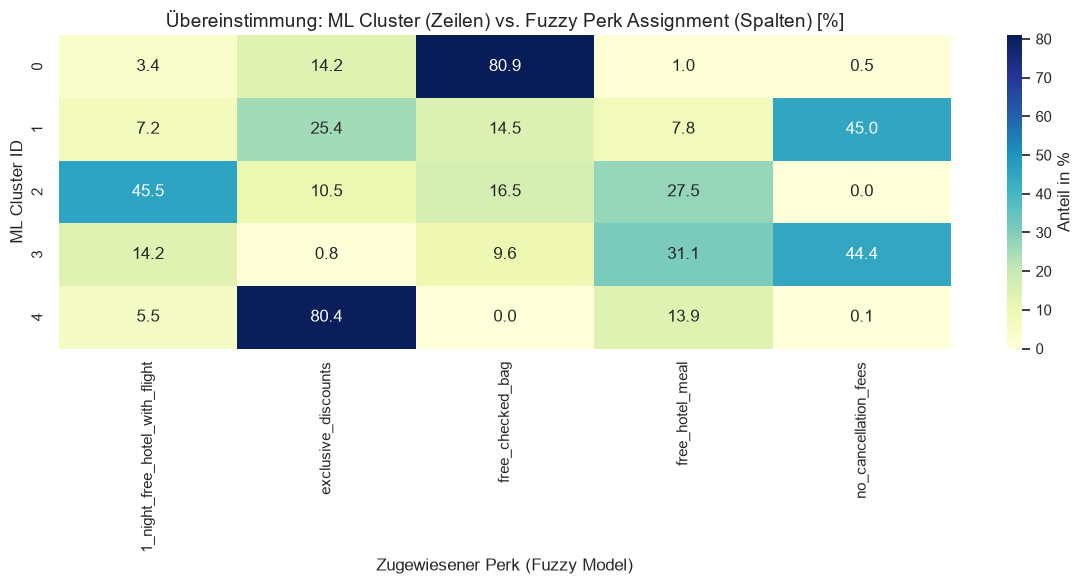

In [5]:
# Merge mit den Fuzzy-Perks
df_comparison = df_indices.merge(df_fuzzy, on='user_id')

# Kreuztabelle erstellen
ct = pd.crosstab(
    df_comparison['cluster_ml'], 
    df_comparison['assigned_perk'], 
    normalize='index'
) * 100

plt.figure(figsize=(12, 6))
sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Anteil in %'})
plt.title("Übereinstimmung: ML Cluster (Zeilen) vs. Fuzzy Perk Assignment (Spalten) [%]", fontsize=14)
plt.xlabel("Zugewiesener Perk (Fuzzy Model)")
plt.ylabel("ML Cluster ID")
plt.tight_layout()
plt.show()